# Hierarchical Clustering: A Tree of Wines

**Family:** Unsupervised learning | **Level:** Beginner | **Dataset:** `wine` | **Runs on:** CPU, about 1 minute(s)

Build a dendrogram and cut it at the level you need.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How agglomerative merging works
- How linkage choice changes the tree
- How to read a dendrogram
- What the cophenetic correlation measures

**Prerequisites:**

- Distances and vectors
- Standardising features

**Skills you will have afterwards:**

- Pick settings without labels
- Check stability
- Compare with a reference labelling

## 2. Real-World Problem

**Context.** Taxonomies and product families are nested, not flat.

**The problem.** Build a nested grouping of wines from chemical measurements.

**Why it matters.** A tree lets an analyst choose the level of detail afterwards.

**Why machine learning.** Similarity from many measurements defines the tree.

**Why this algorithm.** Hierarchical clustering needs no k in advance and shows structure at all scales.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Hierarchical Grouping to Optimize an Objective Function

- **Type:** foundational paper
- **Authors:** Ward, J. H.
- **Year and venue:** 1963, Journal of the American Statistical Association 58(301):236-244
- **DOI or URL:** https://doi.org/10.1080/01621459.1963.10500845
- **Verification:** Crossref 2026-11-17
- **Research objective:** Group items by merging the pair that least increases within group variance.
- **Methodology:** Agglomerative merging with an error sum of squares criterion.
- **Dataset:** Small example from personnel classification.
- **Main findings:** Gives compact groups with a clear merge order.
- **Limitations:** Quadratic memory and time, assumes Euclidean geometry.

### Silhouettes: A graphical aid to the interpretation and validation of cluster analysis

- **Type:** foundational paper
- **Authors:** Rousseeuw, P. J.
- **Year and venue:** 1987, Journal of Computational and Applied Mathematics 20:53-65
- **DOI or URL:** https://doi.org/10.1016/0377-0427(87)90125-7
- **Verification:** Crossref 2026-11-17
- **Research objective:** Provide a score of how well each point fits its cluster.
- **Methodology:** Compare mean distance within the cluster with mean distance to the nearest other cluster.
- **Dataset:** Small illustrative examples.
- **Main findings:** The silhouette value runs from -1 to 1 and supports choosing the number of clusters.
- **Limitations:** Favours convex clusters and is costly on large data.

**Relationship to this notebook.** Ward defines the merge criterion minimising the increase of within cluster variance. We use it as one of four linkages. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Procedure.** Start with every row as its own cluster. Repeatedly merge the two closest clusters until one remains.

**Linkages.** Single: smallest pairwise distance. Complete: largest. Average: mean pairwise. Ward: merge that increases total within cluster variance least,

$$\Delta(A,B) = \frac{|A||B|}{|A|+|B|}\lVert \bar x_A - \bar x_B \rVert^2$$

**Cophenetic correlation.** Correlation between original pairwise distances and the tree distances at which pairs first join. Close to 1 means the tree preserves distances.

**Limits.** $O(n^2)$ memory, merges cannot be undone, single linkage chains.

## 5. Dataset Introduction

**Wine**, UCI, licence CC BY 4.0, DOI 10.24432/C5PC7J. 178 rows, 13 chemical measurements (alcohol, malic acid, ash, magnesium, phenols, flavanoids, colour intensity, proline and others). Target `cultivar`, three classes. Limits: one region, tiny sample.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from ml_lab.data import load_dataset
from ml_lab.evaluation import internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "hierarchical_clustering"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

bundle = load_dataset("wine")
X_raw = bundle.X
y_true = bundle.y          # evaluation only
print("shape:", X_raw.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
shape: (178, 13)


,source
title,Wine recognition
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/109/wine
license,CC BY 4.0
doi,10.24432/C5PC7J
rows,178
features,13
limits,"Three cultivars from one Italian region, very ..."


## 6. Exploratory Data Analysis

We check size, missing values, label balance and feature relations. The reference labels are used for evaluation only, never for fitting. 

Rows and columns: (178, 13)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


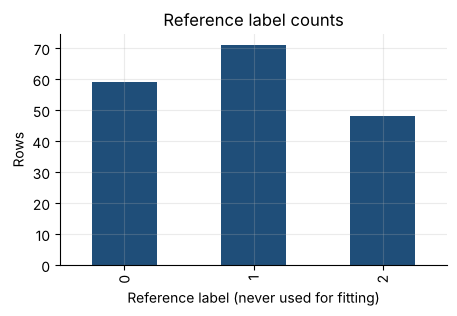

Mean absolute correlation between features: 0.281


In [2]:
print("Rows and columns:", X_raw.shape)
print("Missing values:", int(X_raw.isna().sum().sum()))
display(X_raw.describe().T.head(15).round(3))
fig, ax = plt.subplots(figsize=(5, 3))
pd.Series(y_true).value_counts().sort_index().plot.bar(ax=ax)
ax.set_xlabel("Reference label (never used for fitting)"); ax.set_ylabel("Rows"); ax.set_title("Reference label counts")
plt.show()
corr = X_raw.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print("Mean absolute correlation between features:", round(float(corr.mean()), 3))

## 7. Data Preprocessing

Features are standardised because linkage uses Euclidean distance. No labels enter this step.

In [3]:
X = StandardScaler().fit_transform(X_raw)
print(X.shape)

(178, 13)


## 8. Algorithm Implementation

### 8.1 Concept

The tree records the order and the height of every merge. Cutting at a height gives a flat clustering.

### 8.2 Python implementation from scratch

We implement naive single linkage on 40 rows and compare the merge heights with scipy.

In [4]:
from scipy.cluster.hierarchy import linkage
sub = X[:40]
dist = np.sqrt(((sub[:, None] - sub[None]) ** 2).sum(axis=2))
np.fill_diagonal(dist, np.inf)
clusters = {i: [i] for i in range(len(sub))}
heights = []
while len(clusters) > 1:
    keys = list(clusters)
    best = (np.inf, None, None)
    for a in range(len(keys)):
        for b in range(a + 1, len(keys)):
            d = min(dist[i, j] for i in clusters[keys[a]] for j in clusters[keys[b]])
            if d < best[0]:
                best = (d, keys[a], keys[b])
    heights.append(best[0])
    clusters[best[1]] = clusters[best[1]] + clusters.pop(best[2])
ref_heights = linkage(sub, method="single")[:, 2]
print("max difference of merge heights vs scipy:", float(np.abs(np.array(heights) - ref_heights).max()))

max difference of merge heights vs scipy: 0.0


### 8.3 Library implementation

scikit-learn and scipy provide tested implementations.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `method` | Linkage rule. |
| `metric` | Distance, Euclidean for Ward. |
| `n_clusters` / `t` | Where to cut. |

## 9. Model Training

We build trees with four linkages, compare cophenetic correlation, and cut the Ward tree at k chosen by silhouette over k from 2 to 8.

In [5]:
from scipy.cluster.hierarchy import linkage, fcluster, cophenet
from scipy.spatial.distance import pdist
pair = pdist(X)
coph = {}
trees = {}
for method in ["single", "complete", "average", "ward"]:
    Z = linkage(X, method=method)
    trees[method] = Z
    coph[method] = cophenet(Z, pair)[0]
display(pd.Series(coph, name="cophenetic correlation").round(3).to_frame())
sil = {k: internal_scores(X, fcluster(trees["ward"], k, "maxclust"))["Silhouette"] for k in range(2, 9)}
BEST_K = max(sil, key=sil.get)
print("silhouette by k:", {k: round(v, 3) for k, v in sil.items()}, "| chosen k:", BEST_K)
labels = fcluster(trees["ward"], BEST_K, "maxclust") - 1

,cophenetic correlation
single,0.544
complete,0.592
average,0.759
ward,0.662


silhouette by k: {2: 0.267, 3: 0.277, 4: 0.226, 5: 0.187, 6: 0.18, 7: 0.187, 8: 0.188} | chosen k: 3


## 10. Evaluation

Internal scores need no labels: silhouette (higher is better, range -1 to 1), Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better). External scores (ARI and NMI) compare with a reference label that was never used for fitting. A reference label is not the truth about the data. It is one possible grouping.

In [6]:
METRICS = {**internal_scores(X, labels), **external_scores(y_true, labels), "cophenetic_ward": float(coph["ward"])}
CONFIG = {"linkage": "ward", "k": BEST_K}
EXTRA = {"cophenetic": {k: float(v) for k, v in coph.items()}}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="unsupervised", algorithm="AgglomerativeClustering", dataset="wine",
                          task="clustering", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

saved: /home/claude/open-python/experiments/results/hierarchical_clustering.json


,metric
clusters,3.0000
noise_fraction,0.0000
Silhouette,0.2774
Davies_Bouldin,1.4186
Calinski_Harabasz,67.6475
ARI,0.7899
NMI,0.7865
cophenetic_ward,0.6623


## 11. Visualization

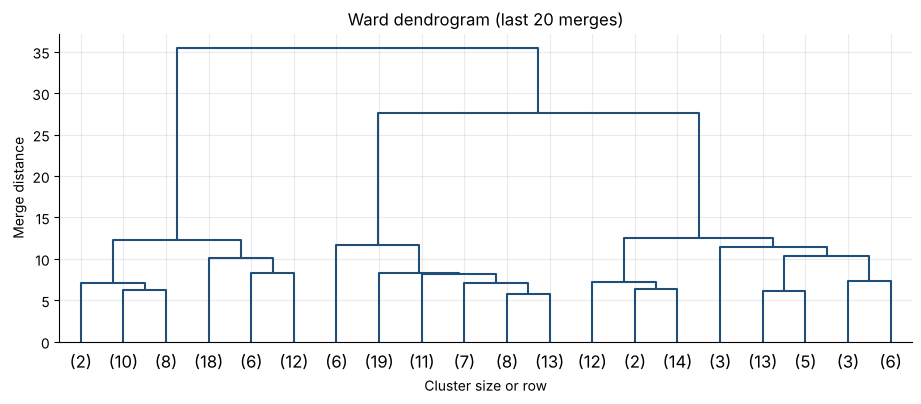

In [7]:
from scipy.cluster.hierarchy import dendrogram
fig, ax = plt.subplots(figsize=(11, 4))
dendrogram(trees["ward"], truncate_mode="lastp", p=20, ax=ax, color_threshold=0)
ax.set_title("Ward dendrogram (last 20 merges)"); ax.set_ylabel("Merge distance"); ax.set_xlabel("Cluster size or row")
save_figure(fig, NOTEBOOK_ID, "dendrogram"); plt.show()

## 12. Interpretation

Long vertical gaps in the dendrogram mark natural cut levels. The cophenetic table shows how faithfully each linkage keeps the original distances.

In [8]:
display(pd.crosstab(pd.Series(labels, name="cluster"), pd.Series(y_true, name="reference label")))
display(X_raw.assign(cluster=labels).groupby("cluster").mean().round(2).T.head(6))

reference label,0,1,2
cluster,,,
0,0,8,48
1,59,5,0
2,0,58,0


cluster,0,1,2
alcohol,13.06,13.67,12.20
malic_acid,3.17,1.97,1.94
ash,2.41,2.46,2.22
alcalinity_of_ash,21.00,17.53,20.21
magnesium,99.86,106.16,92.55
total_phenols,1.69,2.85,2.26


## 13. Experiments and Challenges

### Experiment 1: Linkage comparison

Cut every tree into three clusters and compare silhouette and ARI.

In [9]:
for method, Z in trees.items():
    lab = fcluster(Z, 3, "maxclust") - 1
    s = internal_scores(X, lab)
    print(f"{method:9s} silhouette {s.get('Silhouette', float('nan')):.3f}  ARI {external_scores(y_true, lab)['ARI']:.3f}  sizes {np.bincount(lab)}")

single    silhouette 0.183  ARI -0.007  sizes [  3 174   1]
complete  silhouette 0.204  ARI 0.577  sizes [69 51 58]
average   silhouette 0.158  ARI -0.005  sizes [  3 174   1]


ward      silhouette 0.277  ARI 0.790  sizes [56 64 58]


### Experiment 2: Chaining of single linkage

Single linkage tends to leave one big cluster and tiny leftovers.

In [10]:
lab = fcluster(trees["single"], 5, "maxclust")
print("single linkage cluster sizes:", np.bincount(lab)[1:])
lab = fcluster(trees["ward"], 5, "maxclust")
print("ward cluster sizes:", np.bincount(lab)[1:])

single linkage cluster sizes: [  3 172   1   1   1]
ward cluster sizes: [20 36 64 28 30]


### Experiment 3: Distance metric

Compare Euclidean and Manhattan distance with average linkage.

In [11]:
from sklearn.cluster import AgglomerativeClustering
for metric in ["euclidean", "manhattan", "cosine"]:
    lab = AgglomerativeClustering(n_clusters=3, metric=metric, linkage="average").fit_predict(X)
    print(f"{metric:10s} ARI {external_scores(y_true, lab)['ARI']:.3f}")

euclidean  ARI -0.005
manhattan  ARI 0.473
cosine     ARI 0.785


### Exercises for learners

1. Repeat with `SEED = 7` and report which numbers move.
2. Change the number of rows by sampling 50 percent and compare the result.
3. Add pure noise columns and watch the internal scores.

## 14. Research Discussion

Ward's criterion gives compact clusters and our cophenetic table shows how it compares with other linkages on this data. The chaining experiment illustrates the known weakness of single linkage.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use bootstrap support for tree branches and test linkage stability across resamples.

**Research limitations.** One dataset and one seed for the headline numbers. 

## 15. Summary and Further Reading

**Key takeaways**

- Linkage choice changes the tree.
- Cut where the dendrogram has a large gap.
- Check cophenetic correlation.

**Use cases.** Taxonomies, gene expression, product families.

**Limitations.** Quadratic memory, greedy merges.

**Recommended next notebook.** DBSCAN.

**Further reading.** See `references.md` in this folder.